## 1. Análise exploratória de dados

In [1]:
import pandas as pd
import numpy as np

# 1. RECRIANDO O MESMO DATAFRAME DA PRIMEIRA ETAPA
np.random.seed(42)
dados = {
    'data': pd.date_range(start='2026-01-01', periods=100),
    'vendas': np.random.normal(1000, 200, 100),
    'categoria': np.random.choice(['Eletrônicos', 'Móveis', 'Roupas'], 100),
    'visitas_site': np.random.randint(100, 500, 100),
    'desconto_aplicado': np.random.choice([True, False, np.nan], 100) 
}
df = pd.DataFrame(dados)

# Injetando uma linha duplicada intencionalmente (copiando a linha 0 para o final)
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

display(df)


,data,vendas,categoria,visitas_site,desconto_aplicado
0,2026-01-01,1099.342831,Eletrônicos,211,0.0
1,2026-01-02,972.347140,Móveis,198,NaN
2,2026-01-03,1129.537708,Eletrônicos,252,0.0
3,2026-01-04,1304.605971,Eletrônicos,448,1.0
4,2026-01-05,953.169325,Roupas,483,1.0
...,...,...,...,...,...
97,2026-04-08,1052.211054,Móveis,138,0.0
98,2026-04-09,1001.022691,Móveis,269,0.0
99,2026-04-10,953.082573,Roupas,346,1.0
100,2026-01-01,1099.342831,Eletrônicos,211,0.0


In [2]:

print("=== INSPEÇÃO DE LINHAS ===")

# df.head(n): Retorna as 'n' primeiras linhas. Padrão é 5.
# Excelente para verificar se o DataFrame foi construído corretamente.
print("\n--- Primeiras 3 linhas (head) ---")
print(df.head(3))

# df.tail(n): Retorna as 'n' últimas linhas.
# Aqui, a última linha será a duplicata exata da primeira que inserimos acima.
print("\n--- Últimas 2 linhas (tail) ---")
print(df.tail(2))

# df.sample(n): Sorteia 'n' linhas aleatórias do dataset.
# Evita o viés de analisar apenas o início ou o fim dos dados.
print("\n--- 3 Linhas aleatórias (sample) ---")
print(df.sample(3, random_state=42))



=== INSPEÇÃO DE LINHAS ===

--- Primeiras 3 linhas (head) ---
        data       vendas    categoria  visitas_site  desconto_aplicado
0 2026-01-01  1099.342831  Eletrônicos           211                0.0
1 2026-01-02   972.347140       Móveis           198                NaN
2 2026-01-03  1129.537708  Eletrônicos           252                0.0

--- Últimas 2 linhas (tail) ---
          data       vendas    categoria  visitas_site  desconto_aplicado
100 2026-01-01  1099.342831  Eletrônicos           211                0.0
101 2026-01-01  1099.342831  Eletrônicos           211                0.0

--- 3 Linhas aleatórias (sample) ---
         data       vendas    categoria  visitas_site  desconto_aplicado
30 2026-01-31   879.658678  Eletrônicos           137                1.0
67 2026-03-09  1200.706580  Eletrônicos           287                0.0
62 2026-03-04   778.733005       Roupas           448                NaN


In [3]:

print("\n=== METADADOS E ESTRUTURA ===")

# df.shape: Retorna a tupla (linhas, colunas).
# Como tínhamos 100 linhas e adicionamos 1 duplicata, teremos 101 linhas.
linhas, colunas = df.shape
print(f"\n--- Volumetria (shape) ---")
print(f"O dataset possui {linhas} linhas e {colunas} colunas.")

# df.info(): O "raio-x" do DataFrame.
# Revela a tipagem de cada coluna (float64 para vendas, datetime64 para data, etc.) e o uso de memória.
print("\n--- Informações Estruturais (info) ---")
df.info()



=== METADADOS E ESTRUTURA ===

--- Volumetria (shape) ---
O dataset possui 102 linhas e 5 colunas.

--- Informações Estruturais (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   data               102 non-null    datetime64[us]
 1   vendas             102 non-null    float64       
 2   categoria          102 non-null    str           
 3   visitas_site       102 non-null    int64         
 4   desconto_aplicado  74 non-null     float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 4.1 KB


In [4]:
print("\n=== ESTATÍSTICAS E QUALIDADE DOS DADOS ===")

# Fornece média, desvio padrão, mínimo, máximo e a distribuição em quartis (25%, 50%, 75%).
print("\n--- Estatísticas de Variáveis Numéricas (describe) ---")
display(df.describe())

# Retorna uma Série (uma única dimensão)
display(df['vendas'].describe())

# Retorna um novo DataFrame contendo apenas as colunas especificadas
display(df[['vendas', 'visitas_site']].describe())

# Indica qual é a categoria mais frequente (top) e quantas vezes ela aparece (freq).
print("\n--- Estatísticas de Variáveis Categóricas ---")
display(df.describe(exclude='number'))
# Na coluna 'desconto_aplicado', inserimos np.nan aleatoriamente na criação.
print("\n--- Contagem de Valores Nulos (isnull.sum) ---")
print(df.isnull().sum())

# O resultado será 1, pois copiamos a linha 0 para o final propositalmente.
print("\n--- Contagem de Linhas Duplicadas (duplicated.sum) ---")
print(f"Total de linhas duplicadas: {df.duplicated().sum()}")
print(f"Total de linhas duplicadas ('categoria', 'data'): {df.duplicated(subset=['categoria', 'data']).sum()}")
print(f"Total de linhas duplicadas ('categoria'): {df.duplicated(subset=['categoria']).sum()}")


=== ESTATÍSTICAS E QUALIDADE DOS DADOS ===

--- Estatísticas de Variáveis Numéricas (describe) ---


,data,vendas,visitas_site,desconto_aplicado
count,102,102.000000,102.000000,74.000000
mean,2026-02-18 12:42:21.176470,981.585836,304.490196,0.459459
min,2026-01-01 00:00:00,476.050979,103.000000,0.000000
25%,2026-01-24 06:00:00,881.789820,211.500000,0.000000
50%,2026-02-18 12:00:00,981.234160,292.000000,0.000000
75%,2026-03-15 18:00:00,1099.342831,395.500000,1.000000
max,2026-04-10 00:00:00,1370.455637,497.000000,1.000000
std,NaN,180.603413,114.533297,0.501756


count     102.000000
mean      981.585836
std       180.603413
min       476.050979
25%       881.789820
50%       981.234160
75%      1099.342831
max      1370.455637
Name: vendas, dtype: float64

,vendas,visitas_site
count,102.000000,102.000000
mean,981.585836,304.490196
std,180.603413,114.533297
min,476.050979,103.000000
25%,881.789820,211.500000
50%,981.234160,292.000000
75%,1099.342831,395.500000
max,1370.455637,497.000000



--- Estatísticas de Variáveis Categóricas ---


,data,categoria
count,102,102
unique,NaN,3
top,NaN,Eletrônicos
freq,NaN,36
mean,2026-02-18 12:42:21.176470,NaN
min,2026-01-01 00:00:00,NaN
25%,2026-01-24 06:00:00,NaN
50%,2026-02-18 12:00:00,NaN
75%,2026-03-15 18:00:00,NaN
max,2026-04-10 00:00:00,NaN



--- Contagem de Valores Nulos (isnull.sum) ---
data                  0
vendas                0
categoria             0
visitas_site          0
desconto_aplicado    28
dtype: int64

--- Contagem de Linhas Duplicadas (duplicated.sum) ---
Total de linhas duplicadas: 2
Total de linhas duplicadas ('categoria', 'data'): 2
Total de linhas duplicadas ('categoria'): 99


In [5]:

print("\n=== ANÁLISE DE FREQUÊNCIA ===")

# df.value_counts(): Conta a frequência absoluta de cada categoria em uma coluna.
print("\n--- Contagem de Vendas por Categoria (value_counts) ---")
print(df['categoria'].value_counts())

# normalize=True: Transforma a contagem em proporção (de 0 a 1). Multiplicado por 100 vira porcentagem.
print("\n--- Percentual de Aplicação de Descontos ---")
print(df['desconto_aplicado'].value_counts(normalize=True) * 100)


=== ANÁLISE DE FREQUÊNCIA ===

--- Contagem de Vendas por Categoria (value_counts) ---
categoria
Eletrônicos    36
Roupas         36
Móveis         30
Name: count, dtype: int64

--- Percentual de Aplicação de Descontos ---
desconto_aplicado
0.0    54.054054
1.0    45.945946
Name: proportion, dtype: float64


## Visualização

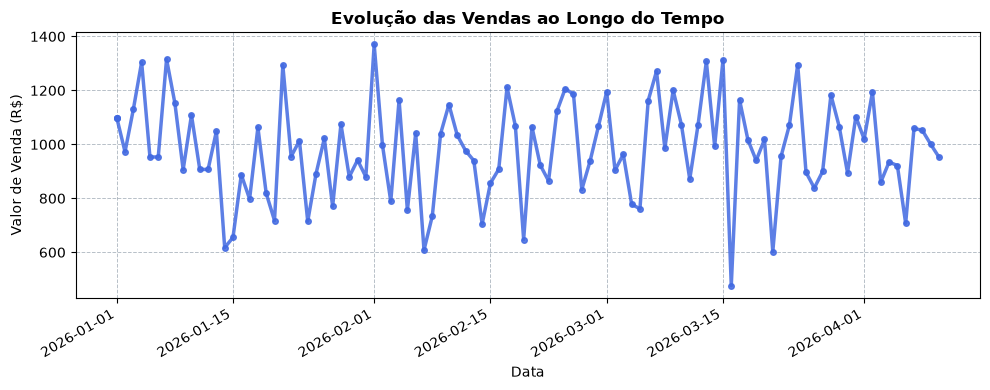

In [7]:
import matplotlib.pyplot as plt

# ==========================================
# 1. GRÁFICO DE LINHA (Evolução Temporal)
# ==========================================
# Dica: Para gráficos de linha temporais no Pandas, é melhor definir a coluna de datas como o "índice" do DataFrame temporariamente.
df_temporal = df.set_index('data').sort_index()

# Estilizando a linha principal dos dados
df_temporal['vendas'].plot(
    kind='line', 
    color='royalblue',    # Uma cor azul mais moderna que o 'blue' padrão
    figsize=(10, 4),
    linewidth=2.5,        # Linha mais grossa para dar destaque
    linestyle='-',        # Mantém a linha sólida (tente '--' para ver a diferença)
    marker='o',           # Coloca uma bolinha em cada dia de venda
    markersize=4,         # Tamanho da bolinha
    alpha=0.85            # Leve transparência
)

plt.title('Evolução das Vendas ao Longo do Tempo', fontweight='bold')
plt.ylabel('Valor de Venda (R$)')
plt.xlabel('Data')

# Estilizando as linhas de grade (Grid)
plt.grid(
    True, 
    color='slategray',    # Cor cinza/azulada neutra
    linestyle='--',       # Linhas tracejadas em vez de sólidas
    linewidth=0.7,        # Linhas mais finas que a linha principal do gráfico
    alpha=0.5             # 50% de transparência para ficar no "fundo"
)

# plt.tight_layout() ajusta as margens automaticamente antes de exibir
plt.tight_layout()
plt.show()


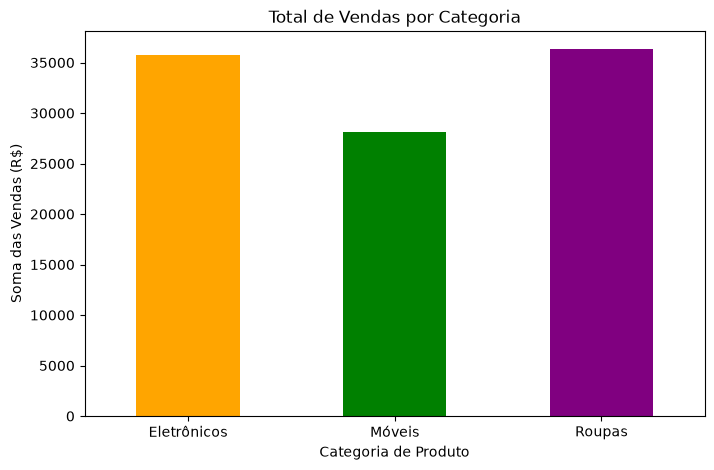

In [8]:

# ==========================================
# 2. GRÁFICO DE BARRAS (Comparação Categórica)
# ==========================================
# Primeiro, agrupamos os dados por categoria e somamos as vendas de cada uma
vendas_por_categoria = df.groupby('categoria')['vendas'].sum()

# kind='bar' gera barras verticais. Se os nomes das categorias fossem longos, usaríamos 'barh' (horizontal)
vendas_por_categoria.plot(kind='bar', color=['orange', 'green', 'purple'], figsize=(8, 5))
plt.title('Total de Vendas por Categoria')
plt.ylabel('Soma das Vendas (R$)')
plt.xlabel('Categoria de Produto')
plt.xticks(rotation=0) # Mantém os nomes das categorias na horizontal para facilitar a leitura
plt.show()



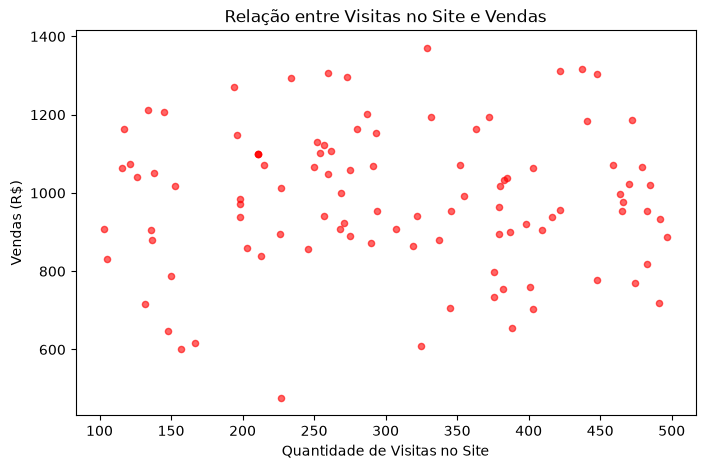

In [9]:

# ==========================================
# 3. GRÁFICO DE DISPERSÃO (Relação/Correlação)
# ==========================================
# kind='scatter' exige que você defina quem é o eixo X e quem é o eixo Y.
# Queremos ver se mais visitas resultam em mais vendas.
df.plot(kind='scatter', x='visitas_site', y='vendas', color='red', figsize=(8, 5), alpha=0.6)
# O parâmetro 'alpha' (transparência) ajuda a ver quando há muitos pontos sobrepostos
plt.title('Relação entre Visitas no Site e Vendas')
plt.ylabel('Vendas (R$)')
plt.xlabel('Quantidade de Visitas no Site')
plt.show()



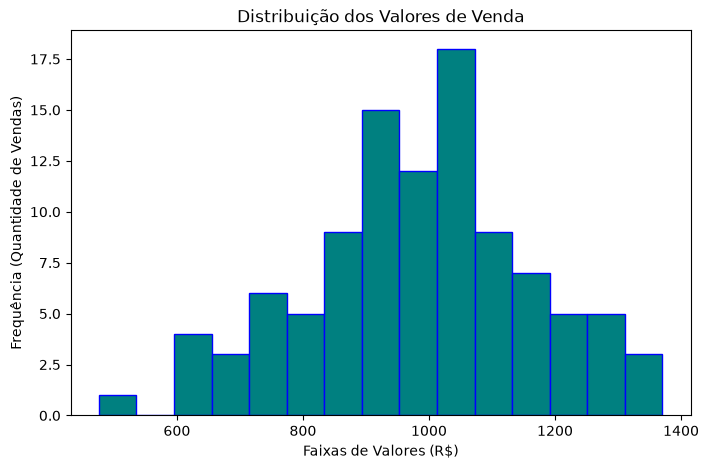

In [11]:
# ==========================================
# 4. HISTOGRAMA (Distribuição Estatística)
# ==========================================
# kind='hist' divide os valores de vendas em intervalos (bins) e conta quantos registros caem em cada faixa.
df['vendas'].plot(kind='hist', bins=15, color='teal', edgecolor='blue', figsize=(8, 5))
# bins=15 divide a base de vendas em 15 "faixas" de valores. edgecolor coloca uma borda preta nas barras.
plt.title('Distribuição dos Valores de Venda')
plt.ylabel('Frequência (Quantidade de Vendas)')
plt.xlabel('Faixas de Valores (R$)')
plt.show()

## Estilização

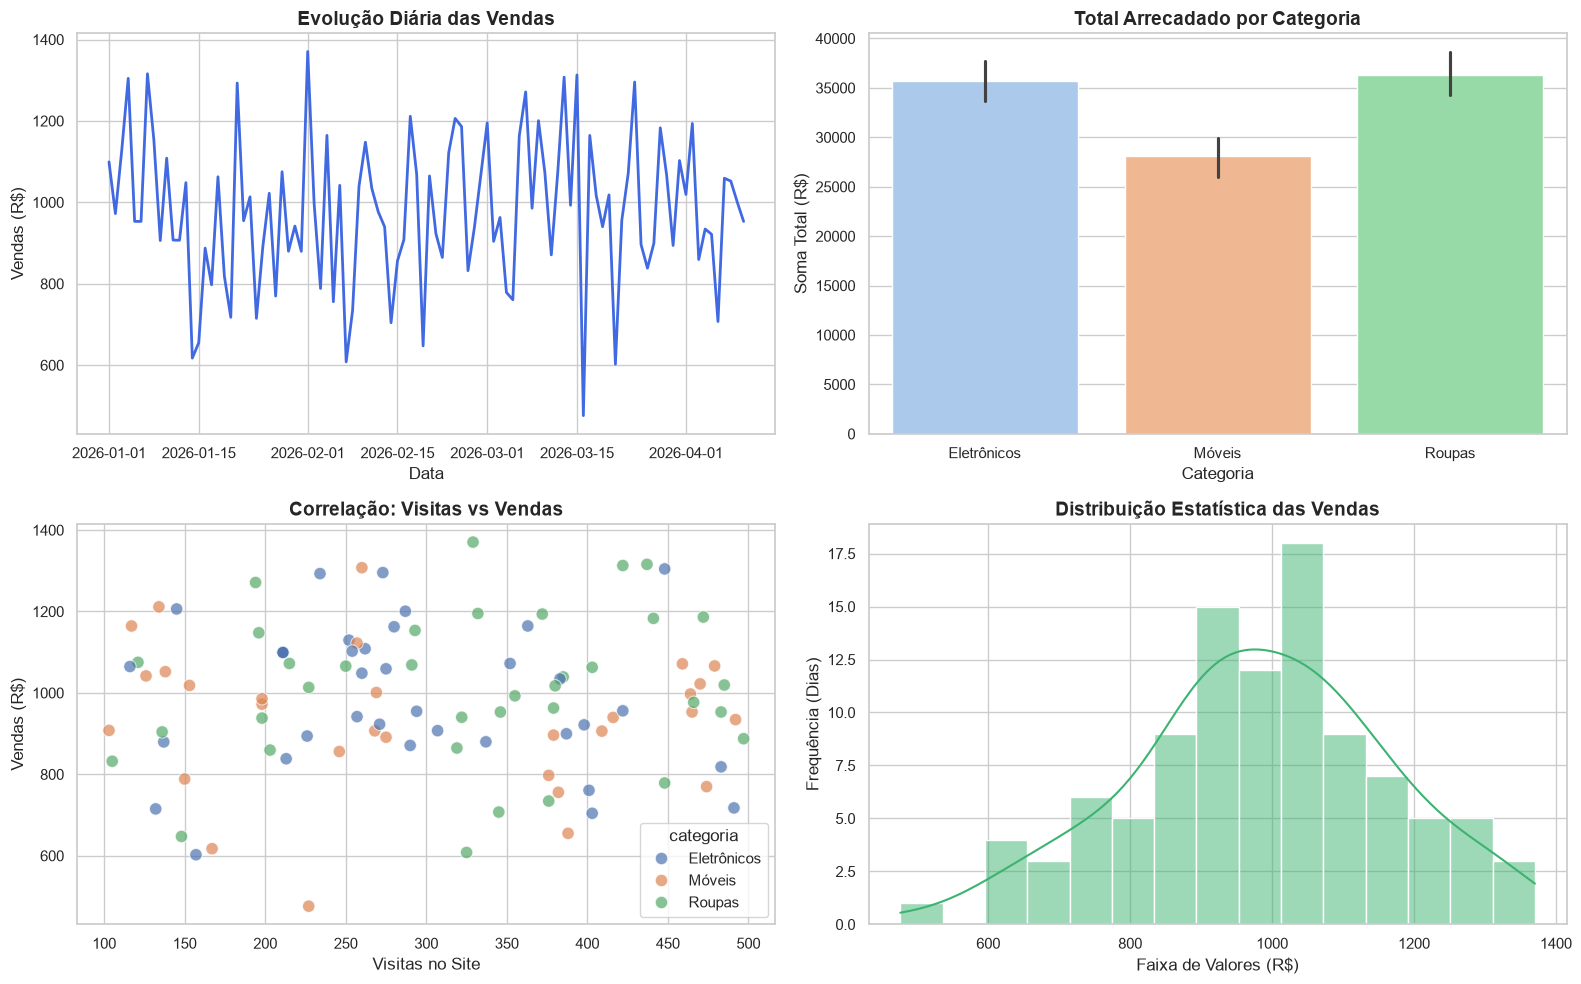

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. RECRIANDO O MESMO DATAFRAME
# np.random.seed(42)
# dados = {
#     'data': pd.date_range(start='2026-01-01', periods=100),
#     'vendas': np.random.normal(1000, 200, 100),
#     'categoria': np.random.choice(['Eletrônicos', 'Móveis', 'Roupas'], 100),
#     'visitas_site': np.random.randint(100, 500, 100),
#     'desconto_aplicado': np.random.choice([True, False, np.nan], 100)
# }
# df = pd.DataFrame(dados)
# df = pd.concat([df, df.iloc[[0]]], ignore_index=True) # Duplicata injetada


# ==========================================
# CUSTOMIZAÇÃO GLOBAL
# ==========================================
# Aplica um tema visual profissional para todos os gráficos (fundo branco com grid)
sns.set_theme(style="whitegrid", palette="muted")


# ==========================================
# CRIAÇÃO DO LAYOUT (SUBPLOTS)
# ==========================================
# Cria uma figura grande (16x10 polegadas) dividida em 2 linhas e 2 colunas
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10))


# --- GRÁFICO 1: LINHA (Superior Esquerdo -> axes[0, 0]) ---
# O Seaborn lida bem com datas no eixo X automaticamente
sns.lineplot(
    data=df, x='data', y='vendas', 
    ax=axes[0, 0], 
    color='royalblue', linewidth=2
)
axes[0, 0].set_title('Evolução Diária das Vendas', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Data')
axes[0, 0].set_ylabel('Vendas (R$)')


# --- GRÁFICO 2: BARRA (Superior Direito -> axes[0, 1]) ---
# Diferente do Pandas, o barplot do Seaborn não exige groupby prévio!
# estimator=np.sum diz ao Seaborn para somar os valores (o padrão dele é calcular a média)
# hue='categoria' colore cada barra com uma cor diferente da paleta
sns.barplot(
    data=df, x='categoria', y='vendas', 
    estimator=np.sum, # Importante: somar as vendas, não a média
    ax=axes[0, 1], 
    hue='categoria', palette='pastel', legend=False 
)
axes[0, 1].set_title('Total Arrecadado por Categoria', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Categoria')
axes[0, 1].set_ylabel('Soma Total (R$)')


# --- GRÁFICO 3: DISPERSÃO (Inferior Esquerdo -> axes[1, 0]) ---
# Customização avançada: O 'hue' separa os pontos por categoria através de cores.
# O 'size' pode alterar o tamanho das bolinhas (aqui fixamos s=80 para facilitar a visualização)
sns.scatterplot(
    data=df, x='visitas_site', y='vendas', 
    hue='categoria', palette='deep', # Colore os pontos dependendo da categoria
    ax=axes[1, 0], 
    s=80, alpha=0.7 # s = tamanho do ponto, alpha = transparência
)
axes[1, 0].set_title('Correlação: Visitas vs Vendas', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Visitas no Site')
axes[1, 0].set_ylabel('Vendas (R$)')


# --- GRÁFICO 4: HISTOGRAMA COM CURVA DE DENSIDADE (Inferior Direito -> axes[1, 1]) ---
# kde=True adiciona uma linha de tendência (Kernel Density Estimate) mostrando o formato da curva normal
sns.histplot(
    data=df, x='vendas', 
    kde=True, 
    ax=axes[1, 1], 
    color='mediumseagreen', bins=15
)
axes[1, 1].set_title('Distribuição Estatística das Vendas', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Faixa de Valores (R$)')
axes[1, 1].set_ylabel('Frequência (Dias)')


# ==========================================
# FINALIZAÇÃO DO LAYOUT
# ==========================================
# Ajusta automaticamente o espaçamento entre os subplots para que os títulos e eixos não se sobreponham
plt.tight_layout()
plt.show()

## Algumas análizes

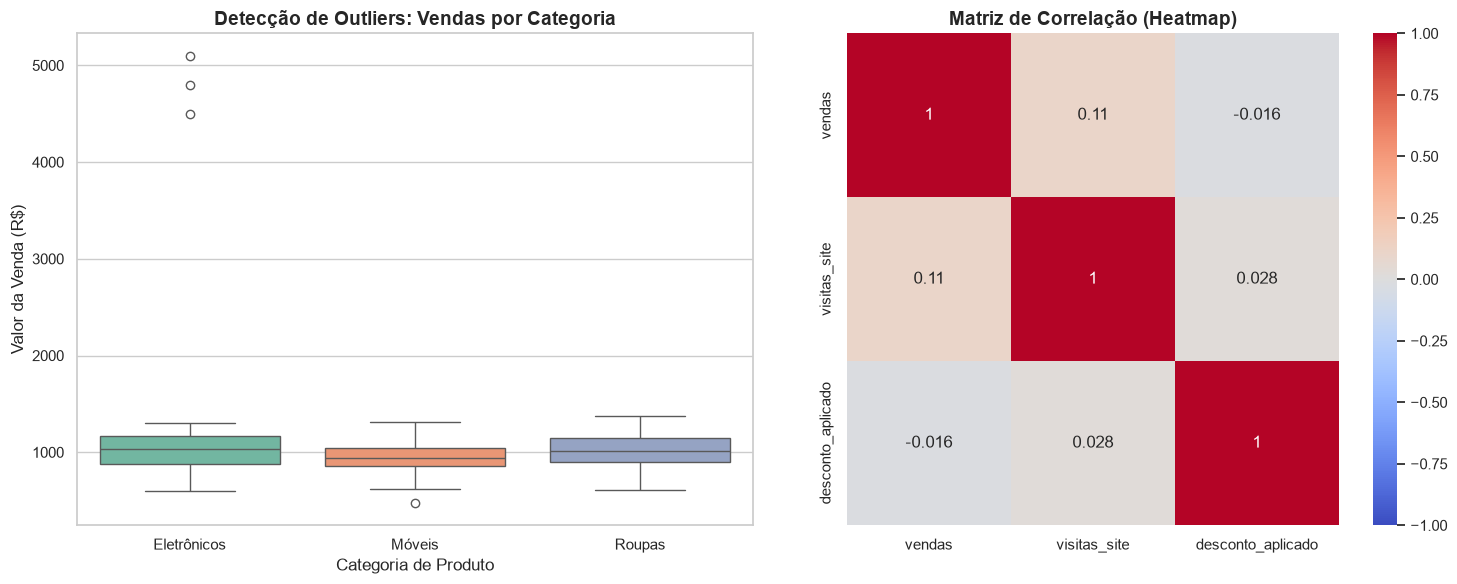

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. RECRIANDO O DATAFRAME
np.random.seed(42)
dados = {
    'data': pd.date_range(start='2026-01-01', periods=100),
    'vendas': np.random.normal(1000, 200, 100),
    'categoria': np.random.choice(['Eletrônicos', 'Móveis', 'Roupas'], 100),
    'visitas_site': np.random.randint(100, 500, 100),
    'desconto_aplicado': np.random.choice([True, False, np.nan], 100)
}
df = pd.DataFrame(dados)

# Injetando problemas intencionais (Outliers) para demonstração
# Vamos colocar 3 vendas absurdamente altas na categoria "Eletrônicos"
df.loc[10, 'vendas'] = 4500
df.loc[25, 'vendas'] = 5100
df.loc[70, 'vendas'] = 4800
# Mudando a categoria dessas linhas específicas para garantir que caiam em "Eletrônicos"
df.loc[[10, 25, 70], 'categoria'] = 'Eletrônicos'


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
# ==========================================
# 1. DIAGNÓSTICO DE OUTLIERS (BOXPLOT)
# ==========================================
# O Boxplot separará a distribuição das vendas por categoria
sns.boxplot(
    data=df, x='categoria', y='vendas', 
    ax=axes[0], 
    hue='categoria',      # <-- Adicionado para associar a cor à categoria
    palette='Set2',
    legend=False          # <-- Adicionado para evitar uma legenda redundante
)
axes[0].set_title('Detecção de Outliers: Vendas por Categoria', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Categoria de Produto')
axes[0].set_ylabel('Valor da Venda (R$)')
# Nota visual: Você verá claramente 3 pontos pretos bem acima da "caixa" na coluna Eletrônicos.


# ==========================================
# 2. DIAGNÓSTICO DE CORRELAÇÃO (HEATMAP)
# ==========================================
# Passo 2.1: Para correlação, precisamos usar APENAS as colunas numéricas (números com texto quebram a função)
colunas_numericas = df.select_dtypes(include=[np.number])

# Passo 2.2: Gerar a matriz de correlação estatística (Método de Pearson é o padrão)
matriz_correlacao = colunas_numericas.corr()

# Passo 2.3: Plotar o Mapa de Calor
sns.heatmap(
    matriz_correlacao, 
    annot=True,          # Escreve o número da correlação dentro do quadrado
    cmap='coolwarm',     # Paleta de cores: Azul (frio/negativo), Vermelho (quente/positivo)
    vmin=-1, vmax=1,     # Força a escala a ir de -1 a 1 (limites estatísticos da correlação)
    ax=axes[1],
    square=True          # Mantém as células perfeitamente quadradas
)
axes[1].set_title('Matriz de Correlação (Heatmap)', fontsize=14, fontweight='bold')


plt.tight_layout()
plt.show()